In [3]:
%pip install pandas numpy matplotlib seaborn


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Installation successful!")


Installation successful!


In [6]:
df = pd.read_csv("../dataset/financial_transactions.csv")
budget = pd.read_csv("../dataset/monthly_budget.csv")

print("Transactions loaded:", df.shape)
print("Budget loaded:", budget.shape)

Transactions loaded: (2400, 9)
Budget loaded: (72, 4)


In [7]:
df.head()
df.info()
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 2400 entries, 0 to 2399
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   transaction_id    2400 non-null   str    
 1   date              2400 non-null   str    
 2   department        2400 non-null   str    
 3   region            2400 non-null   str    
 4   transaction_type  2400 non-null   str    
 5   category          2400 non-null   str    
 6   description       2400 non-null   str    
 7   amount            2400 non-null   float64
 8   payment_method    2400 non-null   str    
dtypes: float64(1), str(8)
memory usage: 168.9 KB


,amount
count,2400.000000
mean,1115.073525
std,916.737387
min,105.230000
25%,545.932500
50%,844.075000
75%,1385.242500
max,11442.960000


In [8]:
df['date'] = pd.to_datetime(df['date'])

print(df['date'].dtype)

datetime64[us]


In [9]:
print("Duplicate transaction IDs:",
      df['transaction_id'].duplicated().sum())

print("Duplicate rows:",
      df.duplicated().sum())

Duplicate transaction IDs: 0
Duplicate rows: 0


In [10]:
df.isnull().sum()


transaction_id      0
date                0
department          0
region              0
transaction_type    0
category            0
description         0
amount              0
payment_method      0
dtype: int64

In [11]:
print("Zero or negative amounts:",
      (df['amount'] <= 0).sum())

print("Negative amounts:",
      (df['amount'] < 0).sum())

Zero or negative amounts: 0
Negative amounts: 0


In [12]:
print(df['transaction_type'].value_counts())

print("\nDepartments:")
print(df['department'].value_counts())

print("\nRegions:")
print(df['region'].value_counts())

transaction_type
Expense    1343
Revenue    1057
Name: count, dtype: int64

Departments:
department
Sales         692
Operations    513
Technology    411
Marketing     346
Finance       225
HR            213
Name: count, dtype: int64

Regions:
region
East     629
North    602
South    602
West     567
Name: count, dtype: int64


In [13]:
revenue = df.loc[
    df['transaction_type'] == 'Revenue', 'amount'
].sum()

expenses = df.loc[
    df['transaction_type'] == 'Expense', 'amount'
].sum()

profit = revenue - expenses

print("Total Revenue:", round(revenue, 2))
print("Total Expenses:", round(expenses, 2))
print("Net Profit:", round(profit, 2))

Total Revenue: 1602285.36
Total Expenses: 1073891.1
Net Profit: 528394.26


In [14]:
df['month'] = df['date'].dt.to_period('M')

monthly_finance = df.groupby(
    ['month', 'transaction_type']
)['amount'].sum().unstack()

monthly_finance.head()

transaction_type,Expense,Revenue
month,,
2025-01,81417.08,126999.27
2025-02,108659.46,130436.37
2025-03,90064.51,122944.68
2025-04,91544.16,122651.38
2025-05,72924.32,133071.23


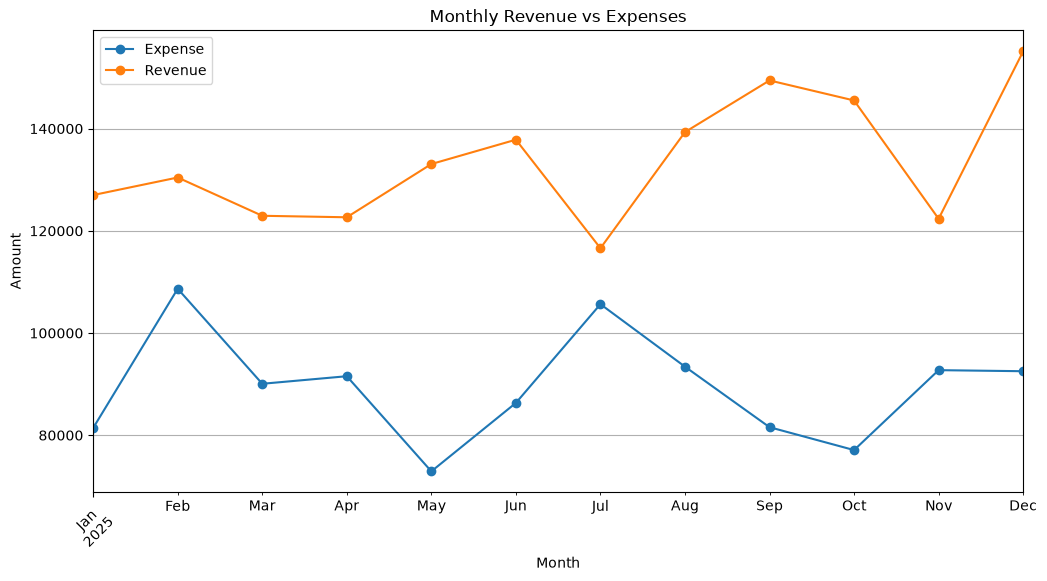

In [15]:
monthly_finance.plot(
    kind='line',
    figsize=(12, 6),
    marker='o'
)

plt.title('Monthly Revenue vs Expenses')
plt.xlabel('Month')
plt.ylabel('Amount')
plt.xticks(rotation=45)
plt.grid(True)
plt.legend()
plt.show()

In [16]:
revenue_by_department = df[
    df['transaction_type'] == 'Revenue'
].groupby('department')['amount'].sum().sort_values(
    ascending=False
)

revenue_by_department

department
Sales         449398.45
Operations    365646.96
Technology    260635.92
Marketing     237401.94
HR            160927.18
Finance       128274.91
Name: amount, dtype: float64

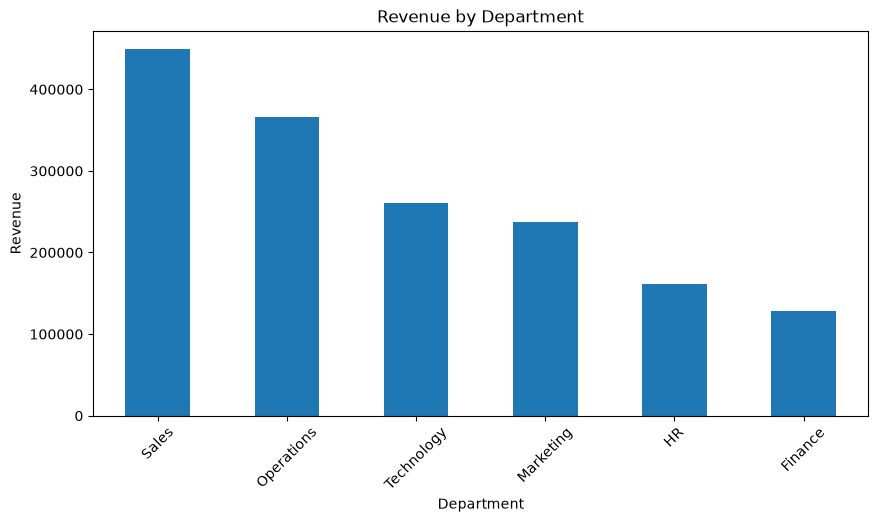

In [17]:
revenue_by_department.plot(
    kind='bar',
    figsize=(10, 5)
)

plt.title('Revenue by Department')
plt.xlabel('Department')
plt.ylabel('Revenue')
plt.xticks(rotation=45)
plt.show()

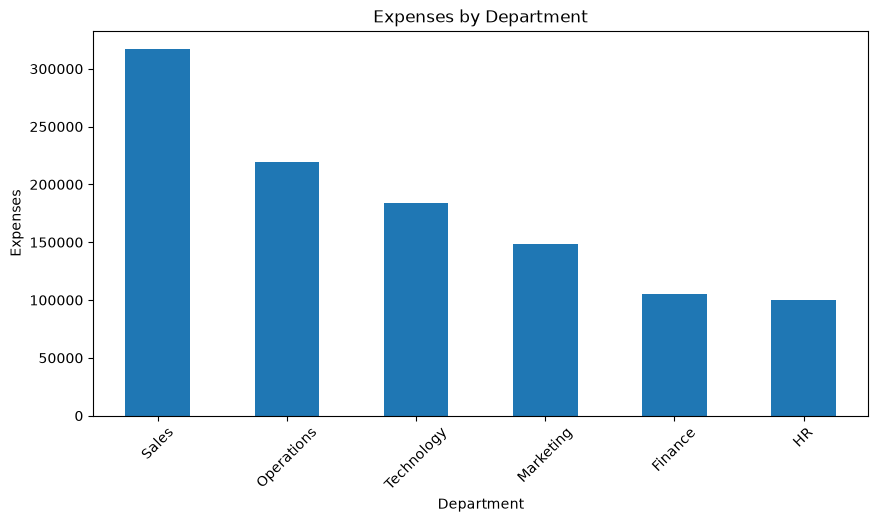

In [19]:
expenses_by_department = df[
    df['transaction_type'] == 'Expense'
].groupby('department')['amount'].sum().sort_values(
    ascending=False
)

expenses_by_department.plot(
    kind='bar',
    figsize=(10, 5)
)

plt.title('Expenses by Department')
plt.xlabel('Department')
plt.ylabel('Expenses')
plt.xticks(rotation=45)
plt.show()

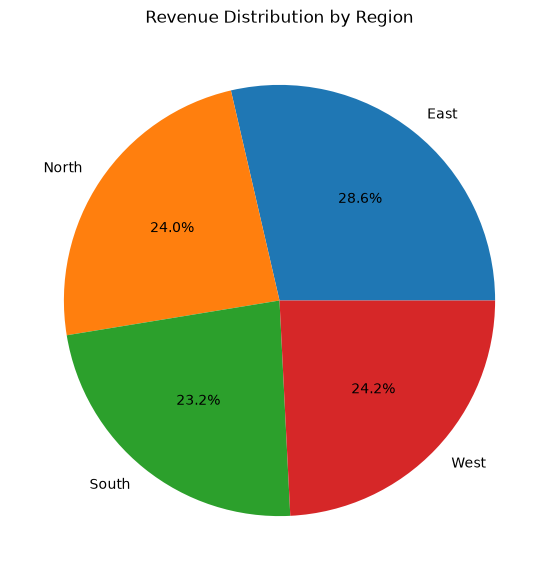

In [20]:
revenue_by_region = df[
    df['transaction_type'] == 'Revenue'
].groupby('region')['amount'].sum()

revenue_by_region.plot(
    kind='pie',
    autopct='%1.1f%%',
    figsize=(7, 7)
)

plt.title('Revenue Distribution by Region')
plt.ylabel('')
plt.show()

In [21]:
import sqlite3
import pandas as pd

print("SQLite connected successfully!")

SQLite connected successfully!


In [23]:
# Create a copy of the transactions dataset
df_sql = df.copy()

# Convert Period column into string
df_sql['month'] = df_sql['month'].astype(str)

# Convert date into string for SQLite
df_sql['date'] = df_sql['date'].astype(str)

print(df_sql.dtypes)

transaction_id          str
date                    str
department              str
region                  str
transaction_type        str
category                str
description             str
amount              float64
payment_method          str
month                   str
dtype: object


In [24]:
import sqlite3

conn = sqlite3.connect("financial_dashboard.db")

df_sql.to_sql(
    "transactions",
    conn,
    if_exists="replace",
    index=False
)

budget.to_sql(
    "budgets",
    conn,
    if_exists="replace",
    index=False
)

print("Database and tables created successfully!")

Database and tables created successfully!


In [25]:
query = """
SELECT name
FROM sqlite_master
WHERE type = 'table';
"""

pd.read_sql_query(query, conn)

,name
0,transactions
1,budgets


In [26]:
query = """
SELECT
    transaction_type,
    ROUND(SUM(amount), 2) AS total_amount
FROM transactions
GROUP BY transaction_type;
"""

result = pd.read_sql_query(query, conn)

display(result)

,transaction_type,total_amount
0,Expense,1073891.10
1,Revenue,1602285.36


In [27]:
SELECT
    department,
    ROUND(SUM(amount), 2) AS total_revenue
FROM transactions
WHERE transaction_type = 'Revenue'
GROUP BY department
ORDER BY total_revenue DESC
LIMIT 1;

IndentationError: unexpected indent (3213276846.py, line 2)

In [28]:
query = """
SELECT
    department,
    ROUND(SUM(amount), 2) AS total_revenue
FROM transactions
WHERE transaction_type = 'Revenue'
GROUP BY department
ORDER BY total_revenue DESC
LIMIT 1;
"""

result = pd.read_sql_query(query, conn)

display(result)

,department,total_revenue
0,Sales,449398.45


In [30]:
query= """
SELECT
    department,
    ROUND(SUM(amount), 2) AS total_expenses
FROM transactions
WHERE transaction_type = 'Expense'
GROUP BY department
ORDER BY total_expenses DESC
LIMIT 1;
"""

In [31]:
query= '''SELECT
    region,
    ROUND(SUM(amount), 2) AS total_revenue
FROM transactions
WHERE transaction_type = 'Revenue'
GROUP BY region
ORDER BY total_revenue DESC;
'''

In [32]:
query='''
SELECT
    strftime('%m', date) AS month,

    ROUND(SUM(CASE
        WHEN transaction_type = 'Revenue'
        THEN amount ELSE 0
    END), 2) AS revenue,

    ROUND(SUM(CASE
        WHEN transaction_type = 'Expense'
        THEN amount ELSE 0
    END), 2) AS expenses,

    ROUND(SUM(CASE
        WHEN transaction_type = 'Revenue'
        THEN amount ELSE -amount
    END), 2) AS profit

FROM transactions
GROUP BY strftime('%m', date)
ORDER BY month;
'''

In [33]:
result = pd.read_sql_query(query, conn)
display(result)

,month,revenue,expenses,profit
0,01,126999.27,81417.08,45582.19
1,02,130436.37,108659.46,21776.91
2,03,122944.68,90064.51,32880.17
3,04,122651.38,91544.16,31107.22
4,05,133071.23,72924.32,60146.91
5,06,137835.51,86317.58,51517.93
6,07,116597.11,105643.41,10953.70
7,08,139321.61,93411.55,45910.06
8,09,149434.11,81566.69,67867.42
9,10,145510.90,77088.63,68422.27


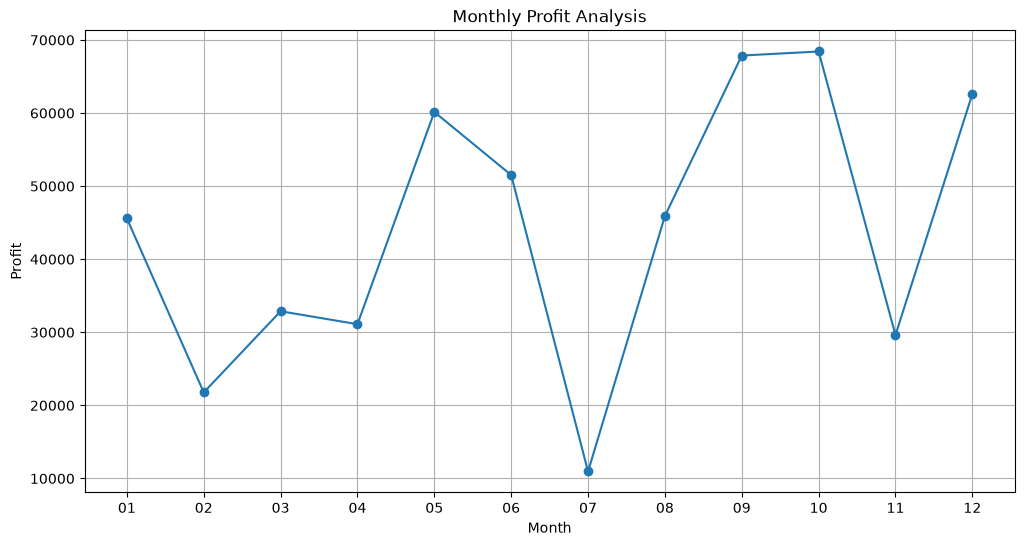

In [34]:
monthly_result = pd.read_sql_query(query, conn)

plt.figure(figsize=(12, 6))

plt.plot(
    monthly_result['month'],
    monthly_result['profit'],
    marker='o'
)

plt.title("Monthly Profit Analysis")
plt.xlabel("Month")
plt.ylabel("Profit")
plt.grid(True)

plt.show()

In [35]:
actuals = df.copy()

actuals['month'] = (
    actuals['date']
    .dt.to_period('M')
    .dt.to_timestamp()
)

monthly_actuals = actuals.groupby(
    ['month', 'department', 'transaction_type']
)['amount'].sum().unstack(fill_value=0).reset_index()

monthly_actuals.head()

transaction_type,month,department,Expense,Revenue
0,2025-01-01,Finance,5683.06,13703.23
1,2025-01-01,HR,7172.43,10128.82
2,2025-01-01,Marketing,7068.14,20868.53
3,2025-01-01,Operations,14205.72,32447.53
4,2025-01-01,Sales,29314.78,27132.68


In [36]:
budget['month'] = pd.to_datetime(budget['month'])

budget.head()

,month,department,budget_revenue,budget_expenses
0,2025-01-01,Sales,211625.08,53545.26
1,2025-01-01,Marketing,36047.95,42803.60
2,2025-01-01,Operations,18261.17,61344.17
3,2025-01-01,Technology,21920.39,46022.19
4,2025-01-01,HR,4993.55,27568.96


In [37]:
financial_data = pd.merge(
    monthly_actuals,
    budget,
    on=['month', 'department'],
    how='left'
)

financial_data.head()

,month,department,Expense,Revenue,budget_revenue,budget_expenses
0,2025-01-01,Finance,5683.06,13703.23,7568.57,24998.79
1,2025-01-01,HR,7172.43,10128.82,4993.55,27568.96
2,2025-01-01,Marketing,7068.14,20868.53,36047.95,42803.60
3,2025-01-01,Operations,14205.72,32447.53,18261.17,61344.17
4,2025-01-01,Sales,29314.78,27132.68,211625.08,53545.26


In [38]:
financial_data['revenue_variance'] = (
    financial_data['Revenue'] -
    financial_data['budget_revenue']
)

financial_data['expense_variance'] = (
    financial_data['Expense'] -
    financial_data['budget_expenses']
)

financial_data.head()

,month,department,Expense,Revenue,budget_revenue,budget_expenses,revenue_variance,expense_variance
0,2025-01-01,Finance,5683.06,13703.23,7568.57,24998.79,6134.66,-19315.73
1,2025-01-01,HR,7172.43,10128.82,4993.55,27568.96,5135.27,-20396.53
2,2025-01-01,Marketing,7068.14,20868.53,36047.95,42803.60,-15179.42,-35735.46
3,2025-01-01,Operations,14205.72,32447.53,18261.17,61344.17,14186.36,-47138.45
4,2025-01-01,Sales,29314.78,27132.68,211625.08,53545.26,-184492.40,-24230.48


In [39]:
# Calculate actual profit
financial_data['actual_profit'] = (
    financial_data['Revenue'] -
    financial_data['Expense']
)

# Calculate budget profit
financial_data['budget_profit'] = (
    financial_data['budget_revenue'] -
    financial_data['budget_expenses']
)

# Calculate profit variance
financial_data['profit_variance'] = (
    financial_data['actual_profit'] -
    financial_data['budget_profit']
)

# Calculate revenue achievement percentage
financial_data['revenue_achievement'] = (
    financial_data['Revenue'] /
    financial_data['budget_revenue']
) * 100

# Display results
financial_data.head()

,month,department,Expense,Revenue,budget_revenue,budget_expenses,revenue_variance,expense_variance,actual_profit,budget_profit,profit_variance,revenue_achievement
0,2025-01-01,Finance,5683.06,13703.23,7568.57,24998.79,6134.66,-19315.73,8020.17,-17430.22,25450.39,181.054413
1,2025-01-01,HR,7172.43,10128.82,4993.55,27568.96,5135.27,-20396.53,2956.39,-22575.41,25531.80,202.838061
2,2025-01-01,Marketing,7068.14,20868.53,36047.95,42803.60,-15179.42,-35735.46,13800.39,-6755.65,20556.04,57.891031
3,2025-01-01,Operations,14205.72,32447.53,18261.17,61344.17,14186.36,-47138.45,18241.81,-43083.00,61324.81,177.685931
4,2025-01-01,Sales,29314.78,27132.68,211625.08,53545.26,-184492.40,-24230.48,-2182.10,158079.82,-160261.92,12.821108


In [40]:
overspending = financial_data[
    financial_data['expense_variance'] > 0
]

overspending[
    ['month', 'department',
     'Expense', 'budget_expenses',
     'expense_variance']
].head(10)

,month,department,Expense,budget_expenses,expense_variance


In [41]:
department_summary = financial_data.groupby(
    'department'
).agg(
    total_revenue=('Revenue', 'sum'),
    total_expenses=('Expense', 'sum'),
    total_profit=('actual_profit', 'sum'),
    budget_profit=('budget_profit', 'sum'),
    profit_variance=('profit_variance', 'sum')
).round(2)

department_summary.sort_values(
    by='total_profit',
    ascending=False
)

,total_revenue,total_expenses,total_profit,budget_profit,profit_variance
department,,,,,
Operations,365646.96,219653.80,145993.16,-558184.52,704177.68
Sales,449398.45,317093.15,132305.30,1825779.68,-1693474.38
Marketing,237401.94,148370.55,89031.39,-97477.12,186508.51
Technology,260635.92,184004.80,76631.12,-307970.22,384601.34
HR,160927.18,99883.36,61043.82,-298130.46,359174.28
Finance,128274.91,104885.44,23389.47,-199558.74,222948.21


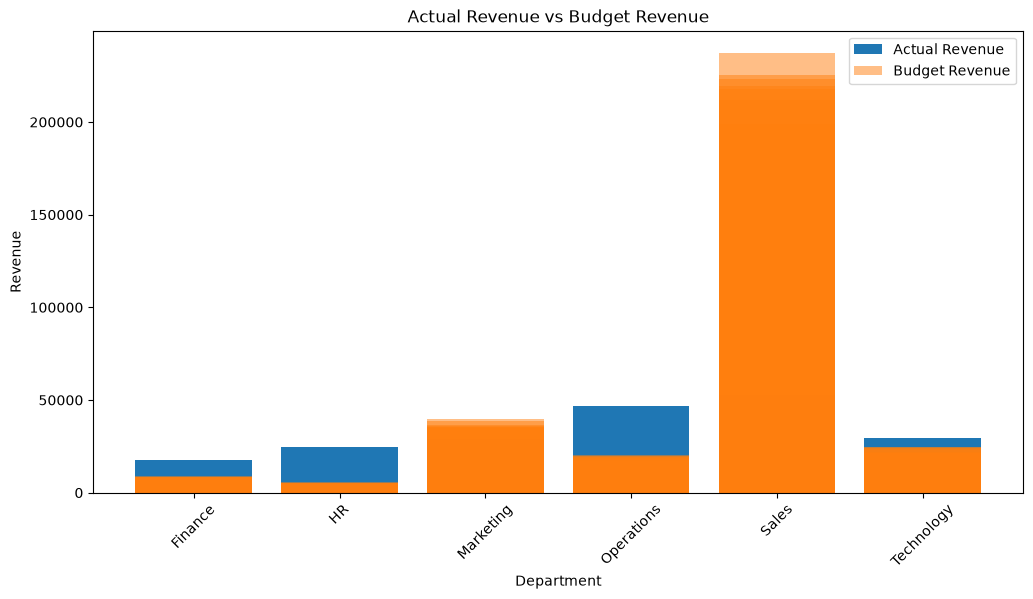

In [42]:
plt.figure(figsize=(12, 6))

plt.bar(
    financial_data['department'],
    financial_data['Revenue'],
    label='Actual Revenue'
)

plt.bar(
    financial_data['department'],
    financial_data['budget_revenue'],
    alpha=0.5,
    label='Budget Revenue'
)

plt.title('Actual Revenue vs Budget Revenue')
plt.xlabel('Department')
plt.ylabel('Revenue')
plt.legend()
plt.xticks(rotation=45)

plt.show()

In [43]:
financial_data.to_csv(
    "../dataset/final_financial_analysis.csv",
    index=False
)

department_summary.to_csv(
    "../dataset/department_summary.csv"
)

print("Final datasets exported successfully!")

Final datasets exported successfully!


In [44]:
department_budget = financial_data.groupby('department').agg(
    actual_revenue=('Revenue', 'sum'),
    budget_revenue=('budget_revenue', 'sum'),
    actual_expenses=('Expense', 'sum'),
    budget_expenses=('budget_expenses', 'sum')
).reset_index()

department_budget

,department,actual_revenue,budget_revenue,actual_expenses,budget_expenses
0,Finance,128274.91,96010.67,104885.44,295569.41
1,HR,160927.18,60315.29,99883.36,358445.75
2,Marketing,237401.94,413882.98,148370.55,511360.10
3,Operations,365646.96,215465.32,219653.80,773649.84
4,Sales,449398.45,2479770.16,317093.15,653990.48
5,Technology,260635.92,268479.31,184004.80,576449.53


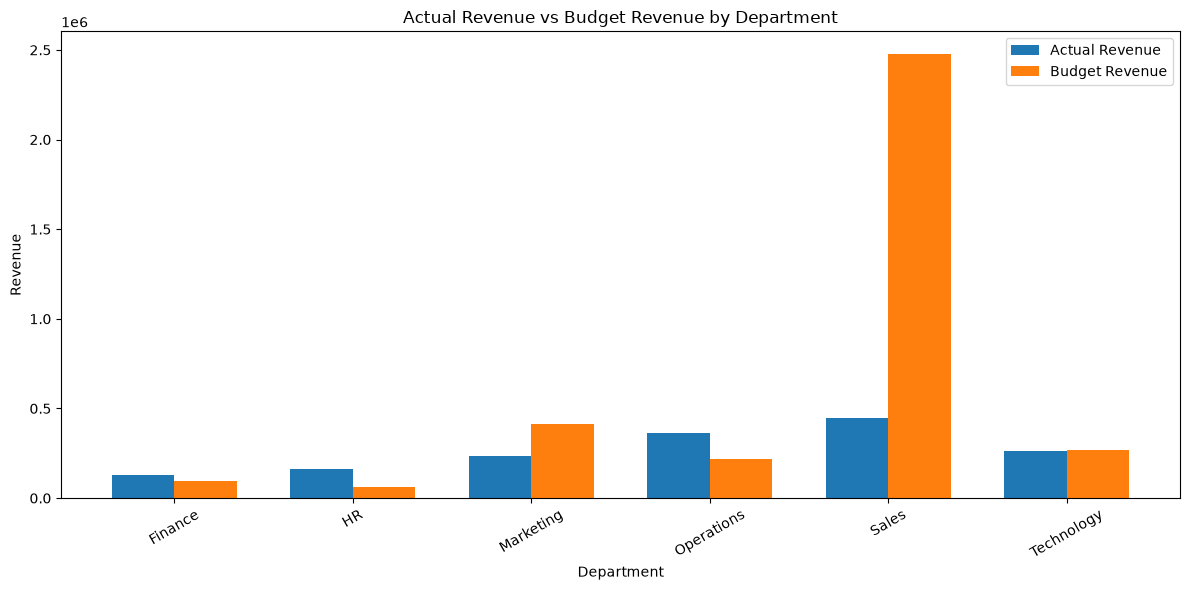

In [45]:
import numpy as np
import matplotlib.pyplot as plt

x = np.arange(len(department_budget))
width = 0.35

plt.figure(figsize=(12, 6))

plt.bar(
    x - width/2,
    department_budget['actual_revenue'],
    width,
    label='Actual Revenue'
)

plt.bar(
    x + width/2,
    department_budget['budget_revenue'],
    width,
    label='Budget Revenue'
)

plt.title('Actual Revenue vs Budget Revenue by Department')
plt.xlabel('Department')
plt.ylabel('Revenue')
plt.xticks(x, department_budget['department'], rotation=30)
plt.legend()
plt.tight_layout()
plt.show()

In [46]:
department_budget['revenue_variance'] = (
    department_budget['actual_revenue'] -
    department_budget['budget_revenue']
)

department_budget['variance_percentage'] = (
    department_budget['revenue_variance'] /
    department_budget['budget_revenue']
) * 100

department_budget

,department,actual_revenue,budget_revenue,actual_expenses,budget_expenses,revenue_variance,variance_percentage
0,Finance,128274.91,96010.67,104885.44,295569.41,32264.24,33.604848
1,HR,160927.18,60315.29,99883.36,358445.75,100611.89,166.809925
2,Marketing,237401.94,413882.98,148370.55,511360.10,-176481.04,-42.640323
3,Operations,365646.96,215465.32,219653.80,773649.84,150181.64,69.701073
4,Sales,449398.45,2479770.16,317093.15,653990.48,-2030371.71,-81.877415
5,Technology,260635.92,268479.31,184004.80,576449.53,-7843.39,-2.921413
